# 04 - Árvore de Decisão

- `DecisionTreeClassifier` e `DecisionTreeRegressor` (Aula 06).
- Critérios de impureza comparados: **Gini × Entropia** (classificação) e
  **MSE (squared_error) × MAE (absolute_error)** (regressão).
- Hiperparâmetros de complexidade (`criterion`, `max_depth`, `min_samples_leaf`,
  `ccp_alpha`, `class_weight`) ajustados com `GridSearchCV` (5 folds) **somente no treino**.
- Uma árvore **sem restrição de profundidade** é treinada para evidenciar o overfitting.
- Árvores não dependem de escala e o dataset não tem valores ausentes, então não há
  normalização/imputação a ajustar (logo, não há como vazar informação do teste).

Métrica de ajuste: **F1** na classificação (classe positiva = doença, com 30% dos casos)
e **RMSE** na regressão (discussão da escolha no notebook 06).

In [1]:
import sys
sys.path.insert(0, "..")
import warnings
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text, plot_tree

from src.config import MODELS, SEED, carregar_split, salvar_fig, salvar_tabela
from src.metrics import SCORING_CV, metricas_classificacao, metricas_regressao
from src.profiling import complexidade

sns.set_style("whitegrid")
dados = {p: carregar_split(p) for p in ("classificacao", "regressao")}
cv = {"classificacao": StratifiedKFold(5, shuffle=True, random_state=SEED),
      "regressao": KFold(5, shuffle=True, random_state=SEED)}

## 1. Ajuste de hiperparâmetros com validação cruzada

In [2]:
grades = {
    "classificacao": (DecisionTreeClassifier(random_state=SEED), {
        "criterion": ["gini", "entropy"],
        "max_depth": [3, 4, 5, 6, 8, 10, None],
        "min_samples_leaf": [1, 10, 20, 50],
        "ccp_alpha": [0.0, 0.001],
        "class_weight": [None, "balanced"],
    }),
    "regressao": (DecisionTreeRegressor(random_state=SEED), {
        "criterion": ["squared_error", "absolute_error"],
        "max_depth": [3, 4, 5, 6, 8, 10],
        "min_samples_leaf": [1, 10, 20, 50, 100],
        "ccp_alpha": [0.0, 1.0],
    }),
}

buscas = {}
for problema, (modelo, grade) in grades.items():
    X_train, X_test, y_train, y_test = dados[problema]
    busca = GridSearchCV(modelo, grade, scoring=SCORING_CV[problema], cv=cv[problema],
                         n_jobs=-1, return_train_score=True)
    busca.fit(X_train, y_train)
    buscas[problema] = busca
    res = pd.DataFrame(busca.cv_results_)
    salvar_tabela(res.drop(columns="params"), f"dt_gridsearch_{problema}", index=False)
    print(f"{problema}: melhores parâmetros {busca.best_params_} | CV = {abs(busca.best_score_):.4f}")

classificacao: melhores parâmetros {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 20} | CV = 0.7636


regressao: melhores parâmetros {'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': 5, 'min_samples_leaf': 50} | CV = 12.0849


### Comparação dos critérios de impureza
Melhor configuração (CV) de cada critério e efeito da profundidade.


classificacao - melhor por critério:


,param_criterion,params,cv,std_test_score
54,entropy,"{'ccp_alpha': 0.0, 'class_weight': None, 'crit...",0.763598,0.020681
181,gini,"{'ccp_alpha': 0.001, 'class_weight': 'balanced...",0.753197,0.013495



regressao - melhor por critério:


,param_criterion,params,cv,std_test_score
44,absolute_error,"{'ccp_alpha': 0.0, 'criterion': 'absolute_erro...",12.168744,0.193491
13,squared_error,"{'ccp_alpha': 0.0, 'criterion': 'squared_error...",12.084905,0.207037


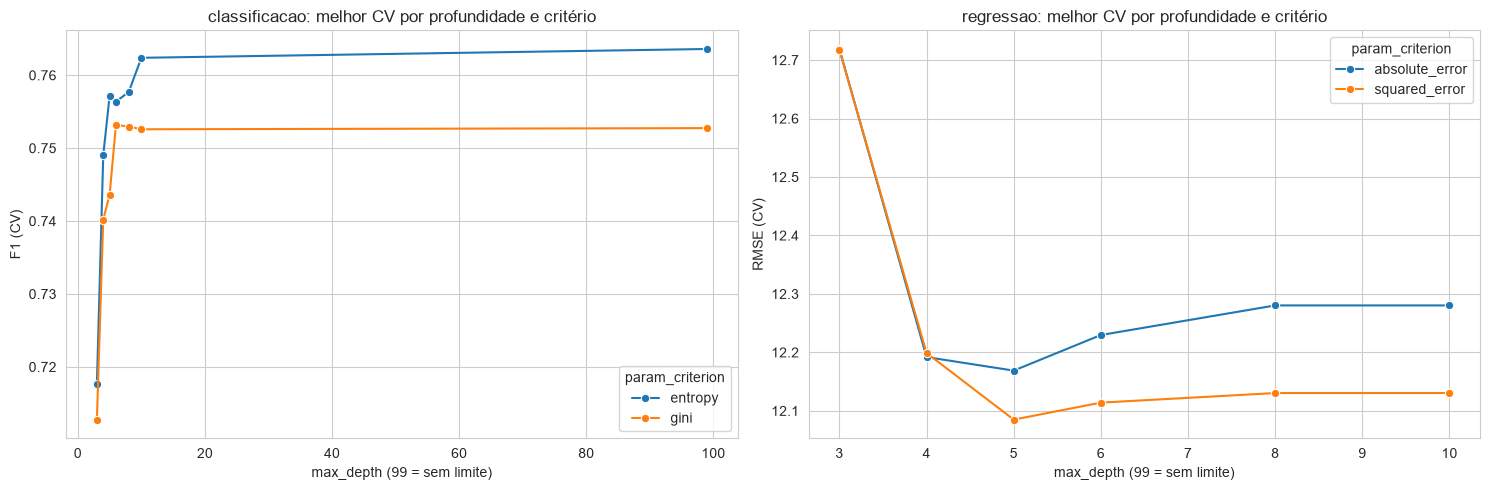

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (problema, busca) in zip(axes, buscas.items()):
    res = pd.DataFrame(busca.cv_results_)
    sinal = -1 if problema == "regressao" else 1
    res["cv"] = sinal * res["mean_test_score"]
    res["prof"] = res["param_max_depth"].fillna(0).astype(int).replace(0, 99)
    melhores = res.loc[res.groupby("param_criterion")["rank_test_score"].idxmin(),
                       ["param_criterion", "params", "cv", "std_test_score"]]
    print(f"\n{problema} - melhor por critério:")
    display(melhores)
    curva = res.groupby(["param_criterion", "prof"])["cv"].agg("max" if sinal == 1 else "min").reset_index()
    sns.lineplot(data=curva, x="prof", y="cv", hue="param_criterion", marker="o", ax=ax)
    ax.set_xlabel("max_depth (99 = sem limite)")
    ax.set_ylabel("F1 (CV)" if sinal == 1 else "RMSE (CV)")
    ax.set_title(f"{problema}: melhor CV por profundidade e critério")
plt.tight_layout()
salvar_fig("dt_criterios")
plt.show()

## 2. Árvore ajustada × árvore sem restrição (overfitting)

In [4]:
linhas, modelos = [], {}
for problema, busca in buscas.items():
    X_train, X_test, y_train, y_test = dados[problema]
    Arvore = DecisionTreeClassifier if problema == "classificacao" else DecisionTreeRegressor
    livre = Arvore(random_state=SEED).fit(X_train, y_train)  # sem restrição
    for nome, m in [("ajustada", busca.best_estimator_), ("sem_restricao", livre)]:
        modelos[(problema, nome)] = m
        joblib.dump(m, MODELS / f"dt_{nome}_{problema}.joblib")
        if problema == "classificacao":
            tr = metricas_classificacao(y_train, m.predict(X_train), m.predict_proba(X_train)[:, 1])["F1"]
            cv_f = "F1"
        else:
            tr = metricas_regressao(y_train, m.predict(X_train))["RMSE"]
            cv_f = "RMSE"
        linhas.append({"problema": problema, "arvore": nome, f"metrica": cv_f,
                       "treino": tr, **complexidade(m)})
comp = pd.DataFrame(linhas)
salvar_tabela(comp, "dt_complexidade", index=False)
comp.round(4)

,problema,arvore,metrica,treino,n_arvores,profundidade,n_nos,n_folhas
0,classificacao,ajustada,F1,0.8242,1,13,347,174
1,classificacao,sem_restricao,F1,1.0000,1,20,1273,637
2,regressao,ajustada,RMSE,11.8224,1,5,59,30
3,regressao,sem_restricao,RMSE,0.0000,1,33,12577,6289


A árvore sem restrição cresce até as folhas ficarem puras: F1 = 1 / RMSE ≈ 0 no treino,
com centenas/milhares de folhas. O desempenho fora do treino (validação cruzada no
notebook 07 e teste no 06) mostra o custo desse ajuste perfeito: **overfitting**.

## 3. Visualização e regras extraídas da árvore ajustada

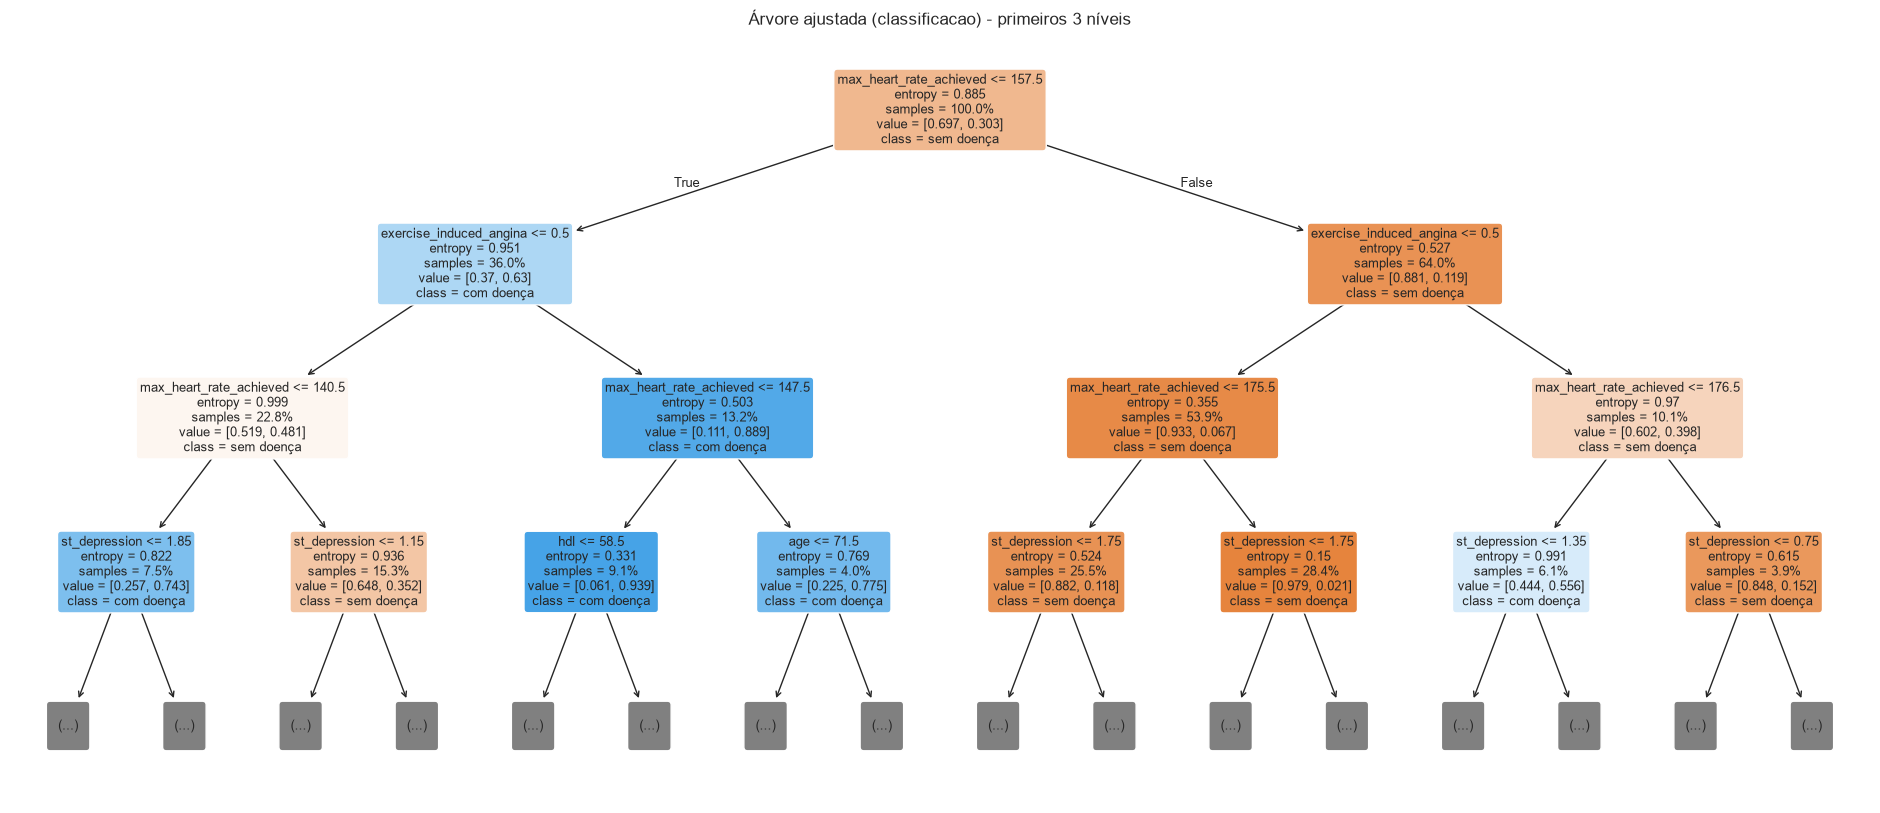

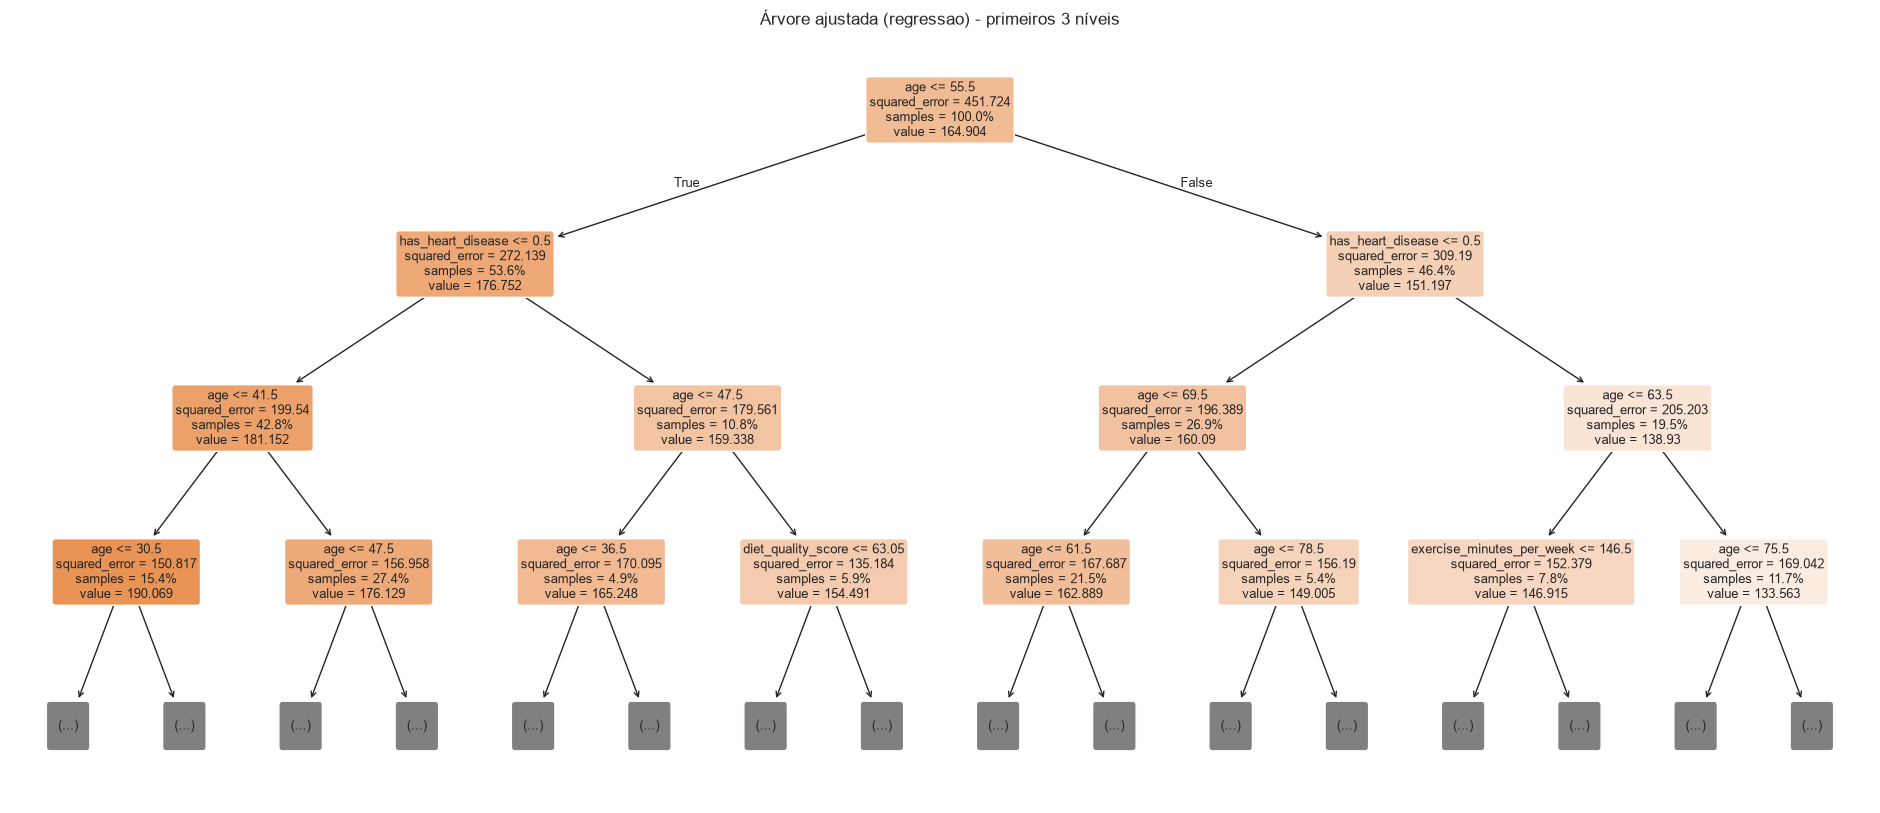

In [5]:
for problema in buscas:
    m = modelos[(problema, "ajustada")]
    X_train = dados[problema][0]
    plt.figure(figsize=(24, 10))
    plot_tree(m, max_depth=3, feature_names=list(X_train.columns), filled=True, rounded=True,
              fontsize=9, proportion=True, impurity=True,
              class_names=["sem doença", "com doença"] if problema == "classificacao" else None)
    plt.title(f"Árvore ajustada ({problema}) - primeiros 3 níveis")
    salvar_fig(f"dt_arvore_{problema}")
    plt.show()

In [6]:
for problema in buscas:
    m = modelos[(problema, "ajustada")]
    texto = export_text(m, feature_names=list(dados[problema][0].columns), max_depth=3,
                        decimals=2, show_weights=False)
    (MODELS.parent / "reports" / "tables" / f"dt_regras_{problema}.txt").write_text(texto, encoding="utf-8")
    print(f"===== {problema} =====\n{texto}")

===== classificacao =====
|--- max_heart_rate_achieved <= 157.50
|   |--- exercise_induced_angina <= 0.50
|   |   |--- max_heart_rate_achieved <= 140.50
|   |   |   |--- st_depression <= 1.85
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- st_depression >  1.85
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- max_heart_rate_achieved >  140.50
|   |   |   |--- st_depression <= 1.15
|   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- st_depression >  1.15
|   |   |   |   |--- truncated branch of depth 6
|   |--- exercise_induced_angina >  0.50
|   |   |--- max_heart_rate_achieved <= 147.50
|   |   |   |--- hdl <= 58.50
|   |   |   |   |--- truncated branch of depth 6
|   |   |   |--- hdl >  58.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- max_heart_rate_achieved >  147.50
|   |   |   |--- age <= 71.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- age >  71.50
|   |   |   |   |--- class: 0
|--- max_heart_r